In [99]:
import pandas as pd
import json 

In [ ]:
reviews = json.load(open('./data/carscom_flat_weighted.json', 'r'))
df = pd.DataFrame(reviews)
df = df[df['found_on_carscom'] == True]
df.columns
#########
listings = json.load(open('./data/autoscout24_combined_data.json', 'r')).get('combined_data' , [])
listings_df = pd.DataFrame(listings)
listings_df.columns

In [101]:
#### bisogna applicare la seguente funzione a listings['make'] e listings['model'] 

def normalize_slug_part(s: pd.Series) -> pd.Series:
    return (
        s.astype(str)
         .str.strip()
         .str.lower()
         .str.replace(r"[\s\-]+", "_", regex=True)
         .str.replace(r"[^a-z0-9_]", "", regex=True)
         .str.replace(r"_+", "_", regex=True)
         .str.strip("_")
    )




### MERGING

In [ ]:
# Normalizza `make` e `model` in `listings_df` per la funzione definita sopra
listings_df['make_norm'] = normalize_slug_part(listings_df.get('make', pd.Series(dtype='object')))
listings_df['model_norm'] = normalize_slug_part(listings_df.get('model', pd.Series(dtype='object')))

# Esegui il merge usando le colonne normalizzate
total_df = pd.merge(listings_df, df, right_on=['marca_norm', 'modello_norm'],
                    left_on=['make_norm', 'model_norm'], how='inner')

# Controllo rapido
total_df.shape
total_df.head(2)
# total_df.drop(columns=['marca_norm', 'modello_norm'], inplace=True)
total_df.head(2)
total_df[['make', 'model']].value_counts().count()

In [ ]:
listings_df.to_csv()

In [ ]:
# Controllo rapido sul dataframe risultante
print('total_df.shape =', total_df.shape)
print('Distinct make/model pairs =', total_df[['make', 'model']].value_counts().count())
total_df.head(5)

In [105]:
total_df.to_csv('./data/combined_listings_reviews.csv', index=False)

In [ ]:
total_df['comfort'].describe()

---------
# drop and parse

In [107]:
total_df = total_df.replace('-', pd.NA)

In [108]:
total_df['year'] = total_df['year'].str.split('-').str[1]

In [ ]:
# variabili da eliminare 

total_df.drop(columns = ['spec_mileage', 'spec_power', 'make_norm' , 'model_norm' , 'marca_norm' ,'modello_norm' , 'fuel_type' , 'title', 
                          'found_on_carscom' , 'seller_zip' , 'seller_country' , 'seller_location' , 'features_count' , 
                          'source' , 'spec_full_service_history' , 'spec_general_inspection', 'spec_offer_number',
                          'spec_year' ] , inplace = True)
total_df.head()


In [110]:
#variabili da portare a numeric 

total_df['spec_empty_weight'] = total_df['spec_empty_weight'].str.replace(',', '').str.replace(' kg', '').astype(float)
total_df['power'] = total_df['power'].str.split('kW').str[0]
#da power bisogna impostare trattino come null 
total_df['power'] = pd.to_numeric(total_df['power'], errors='coerce')
total_df['power'] = total_df['power'].replace('-', pd.NA)
total_df['spec_engine_size'] = total_df['spec_engine_size'].str.replace(',', '').str.replace(' cc', '').astype(float)
total_df['spec_fuel_consumption'] = total_df['spec_fuel_consumption'].str.split().str[0].astype(float)


------------
# collegamento con sql lite 3 

In [111]:
import sqlite3 

# Salva in SQLite (crea automaticamente il database)
conn = sqlite3.connect('my_project.db') 
total_df.to_sql('cars_data', conn, if_exists='replace', index=False)

# Le due query richieste (FAQ 6)
query1 = "SELECT distinct make , model   FROM cars_data WHERE spec_fuel_consumption < 7.0"
result1 = pd.read_sql_query(query1, conn)


query2 = "SELECT make, AVG(price) FROM cars_data GROUP BY make ORDER BY AVG(price) DESC"
result2 = pd.read_sql_query(query2, conn)


conn.close() 


----------


# **Calcolo Metriche Data Quality**
## _before dummification_

In [112]:
# completness 

total_completeness = (total_df.count().sum() / total_df.size) * 100
column_completeness = (total_df.count() / len(total_df) * 100)
print(f'Total Completeness: {total_completeness:.2f}%')

Total Completeness: 98.85%


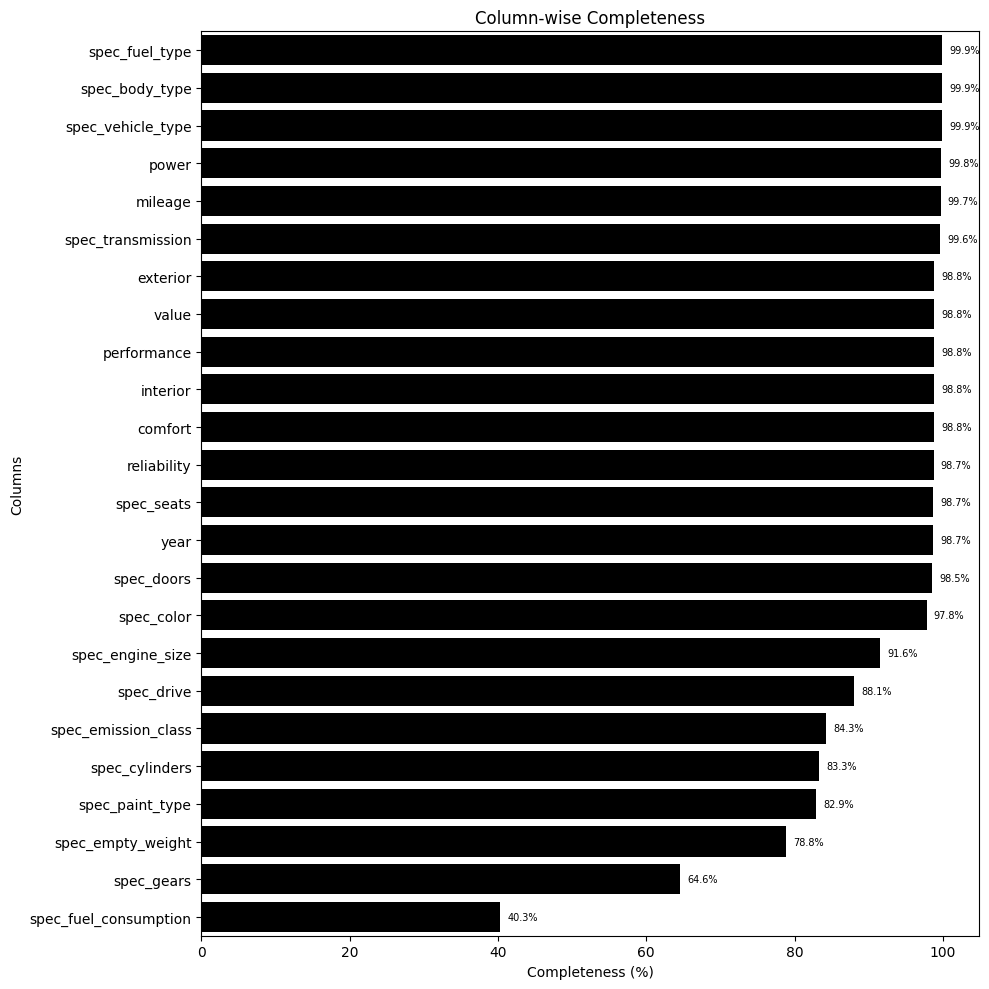

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 10))
column_completeness = column_completeness[column_completeness < 100].sort_values(ascending=False)  # Filtra solo le colonne con meno del 100% di completezza
ax = sns.barplot(x=column_completeness.values, y=column_completeness.index, color='black', orient='h') 
plt.yticks(rotation=0)
plt.ylabel('Columns')
plt.xlabel('Completeness (%)')
plt.title('Column-wise Completeness')

# Aggiungi il valore di completeness alla fine di ogni barra
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}%', 
                xy=(width, p.get_y() + p.get_height() / 2), 
                xytext=(5, 0), 
                textcoords='offset points', 
                ha='left', va='center', fontsize=7)

plt.tight_layout()
plt.show()


In [114]:
# uniqueness 

# 1. Verifica che ID sia univoco (dovrebbe esserlo!)
print(f"Total rows: {len(total_df)}")
print(f"Unique ID: {total_df['id'].nunique()}")
print(f"Duplicated ID: {total_df['id'].duplicated().sum()}")


# 2. Se ID è univoco, non hai duplicati veri
if total_df['id'].nunique() == len(total_df):
    print("Nessun duplicato reale (ID univoci)")
else:
    # Trova quali ID sono duplicati
    dup_ids = total_df[total_df['id'].duplicated(keep=False)]
    print(f"Trovati {len(dup_ids)} ID duplicati:")
    print(dup_ids[['id', 'make', 'model', 'year']].sort_values('id'))

# 3. Per data quality report: usa uniqueness su ID
uniqueness = (total_df['id'].nunique() / len(total_df)) * 100
print(f"\nUniqueness: {uniqueness:.2f}%")

Total rows: 1507
Unique ID: 1504
Duplicated ID: 3
Trovati 6 ID duplicati:


---------
# **Dummification**

In [115]:
total_df.drop_duplicates(inplace=True)
total_df = total_df.query("cumulata != 0")

In [116]:
# dummification delle variabili categoriche 

total_df = pd.get_dummies(total_df, columns=['seller_type', 'spec_drive', 'spec_paint_type' , 'spec_fuel_type', 'spec_transmission', 'spec_color', 'spec_body_type' , 'spec_emission_class', 'spec_vehicle_type'] )

In [117]:
print(total_df.columns.tolist())


['id', 'make', 'model', 'year', 'price', 'mileage', 'power', 'spec_cylinders', 'spec_doors', 'spec_empty_weight', 'spec_engine_size', 'spec_fuel_consumption', 'spec_gears', 'spec_seats', 'feat_360_camera', 'feat_abs', 'feat_adaptive_cruise_control', 'feat_adaptive_headlights', 'feat_air_conditioning', 'feat_air_suspension', 'feat_alarm_system', 'feat_all_season_tyres', 'feat_alloy_wheels', 'feat_alloy_wheels_14', 'feat_alloy_wheels_15', 'feat_alloy_wheels_16', 'feat_alloy_wheels_17', 'feat_alloy_wheels_18', 'feat_alloy_wheels_19', 'feat_alloy_wheels_20', 'feat_alloy_wheels_21', 'feat_alloy_wheels_22', 'feat_alloy_wheels_23', 'feat_ambient_lighting', 'feat_android_auto', 'feat_apple_carplay', 'feat_armrest', 'feat_automatic_climate_control', 'feat_automatic_climate_control_2_zones', 'feat_automatic_climate_control_3_zones', 'feat_automatic_climate_control_4_zones', 'feat_automatically_dimming_interior_mirror', 'feat_auxiliary_heating', 'feat_awning', 'feat_bi_xenon_headlights', 'feat_bi

In [118]:
# Identifica colonne che iniziano con 'feat'
feat_cols = [col for col in total_df.columns if col.startswith('feat')]

print(f"Trovate {len(feat_cols)} colonne che iniziano con 'feat'")

# Verifica che siano effettivamente binarie (0/1)
binary_feat_cols = []
for col in feat_cols:
    unique_vals = total_df[col].dropna().unique()
    if set(unique_vals).issubset({0, 1}):
        binary_feat_cols.append(col)

print(f"Di queste, {len(binary_feat_cols)} sono binarie (0/1)")

# Converti in booleano
total_df[binary_feat_cols] = total_df[binary_feat_cols].astype(bool)

print(f"\nConvertite {len(binary_feat_cols)} colonne in booleano")
print(f"\nPrime 5 colonne convertite: {binary_feat_cols[:5]}")

Trovate 144 colonne che iniziano con 'feat'
Di queste, 144 sono binarie (0/1)

Convertite 144 colonne in booleano

Prime 5 colonne convertite: ['feat_360_camera', 'feat_abs', 'feat_adaptive_cruise_control', 'feat_adaptive_headlights', 'feat_air_conditioning']


In [119]:
total_df.to_csv('./data/combined_listings_reviews_dummified.csv', index=False) 

---------
# **W-PCA** 

In [120]:
import numpy as np

In [121]:
features_row = ['comfort', 'interior', 'performance', 'value', 'exterior']
mask = total_df['reliability'].isna()
total_df.loc[mask, 'reliability'] = total_df.loc[mask, features_row].mean(axis=1)

features = [
    'comfort',
    'interior',
    'performance',
    'value',
    'exterior',
    'reliability'
]

X = total_df[features].values
w = total_df['cumulata'].values  

# normalizzo i pesi
w_norm = w / np.sum(w)

# media pesata
mean_w = np.average(X, axis=0, weights=w_norm)

# varianza pesata
var_w = np.average((X - mean_w)**2, axis=0, weights=w_norm)
std_w = np.sqrt(var_w)

# standardizzazione
X_std = (X - mean_w) / std_w 

# matrice diagonale dei pesi
W = np.diag(w_norm)

# covarianza pesata
cov_w = X_std.T @ W @ X_std 

eigvals, eigvecs = np.linalg.eigh(cov_w)

# ordino in senso decrescente
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx] 

explained_variance_ratio = eigvals / eigvals.sum()

pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(eigvals))],
    'Explained variance ratio': explained_variance_ratio
}) 

X_pca = X_std @ eigvecs

df_pca = pd.DataFrame(
    X_pca[:, :1],  # prime 2 componenti
    columns=['PC1'],
    index=total_df.index
)

total_df = pd.concat([total_df, df_pca], axis=1) 

loadings = pd.DataFrame(
    eigvecs,
    index=features,
    columns=[f'PC{i+1}' for i in range(len(features))]
)

loadings

,PC1,PC2,PC3,PC4,PC5,PC6
comfort,-0.397347,-0.456371,-0.511598,-0.031838,0.608968,0.015895
interior,-0.414746,-0.394520,-0.250748,0.118601,-0.771308,0.021997
performance,-0.429677,0.136184,0.338056,0.727810,0.153141,-0.359708
value,-0.395289,0.531003,-0.236583,-0.469846,-0.069483,-0.529366
exterior,-0.402316,-0.308382,0.707195,-0.478937,0.073101,0.090517
reliability,-0.409106,0.490377,-0.070820,0.071247,0.024883,0.762530


In [122]:
print(total_df.columns.tolist())

['id', 'make', 'model', 'year', 'price', 'mileage', 'power', 'spec_cylinders', 'spec_doors', 'spec_empty_weight', 'spec_engine_size', 'spec_fuel_consumption', 'spec_gears', 'spec_seats', 'feat_360_camera', 'feat_abs', 'feat_adaptive_cruise_control', 'feat_adaptive_headlights', 'feat_air_conditioning', 'feat_air_suspension', 'feat_alarm_system', 'feat_all_season_tyres', 'feat_alloy_wheels', 'feat_alloy_wheels_14', 'feat_alloy_wheels_15', 'feat_alloy_wheels_16', 'feat_alloy_wheels_17', 'feat_alloy_wheels_18', 'feat_alloy_wheels_19', 'feat_alloy_wheels_20', 'feat_alloy_wheels_21', 'feat_alloy_wheels_22', 'feat_alloy_wheels_23', 'feat_ambient_lighting', 'feat_android_auto', 'feat_apple_carplay', 'feat_armrest', 'feat_automatic_climate_control', 'feat_automatic_climate_control_2_zones', 'feat_automatic_climate_control_3_zones', 'feat_automatic_climate_control_4_zones', 'feat_automatically_dimming_interior_mirror', 'feat_auxiliary_heating', 'feat_awning', 'feat_bi_xenon_headlights', 'feat_bi

In [123]:
#total_df.drop(columns = ['comfort', 'interior', 'performance', 'value', 'exterior', 'reliability'], inplace = True )

--------
# **Target Engeneering** 



In [124]:
#se pc1 > mean(pc1) --> appreciate = 1 else appreciate = 0 
mean_pc1 = total_df['PC1'].mean() 
total_df['appreciate'] = (total_df['PC1'] > mean_pc1).astype(bool) 


In [125]:
#encodind 'appreciate' 
total_df['appreciate'].describe()
total_df.to_csv('./data/combined_listings_reviews_final.csv', index=False)

--------
### **DecisionTreeRegressor** and **FEATURE IMPORTANCE**

In [126]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')




# Rimuovi colonne
columns_to_remove = ['comfort', 'interior', 'performance', 'value', 'exterior', 
                     'reliability', 'PC1', 'make', 'model', 'cumulata', 'appreciate', 'id'] 
existing_columns_to_remove = [col for col in columns_to_remove if col in total_df.columns]

y = total_df['appreciate']
X = total_df.drop(columns=existing_columns_to_remove)

# Rimuovi colonne object (stringhe)
object_cols = X.select_dtypes(include=['object']).columns
if len(object_cols) > 0:
    X = X.drop(columns=object_cols)

# Converti booleani in int
bool_cols = X.select_dtypes(include=['bool']).columns
if len(bool_cols) > 0:
    X[bool_cols] = X[bool_cols].astype(int)

# Gestisci NaN
if X.isnull().sum().sum() > 0:
    for col in X.columns:
        if X[col].isnull().sum() > 0:
            X[col].fillna(X[col].median(), inplace=True)


BASELINE:
Accuracy: 0.8020
Precision: 0.7576
Recall: 0.6818
F1: 0.7177
ROC-AUC: 0.8571






BEST PARAMS:
{'learning_rate': 0.1, 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200, 'subsample': 1.0}
CV ROC-AUC: 0.8624

TUNED:
Accuracy: 0.8322
Precision: 0.7830
Recall: 0.7545
F1: 0.7685
ROC-AUC: 0.8838

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False       0.86      0.88      0.87       188
        True       0.78      0.75      0.77       110

    accuracy                           0.83       298
   macro avg       0.82      0.82      0.82       298
weighted avg       0.83      0.83      0.83       298



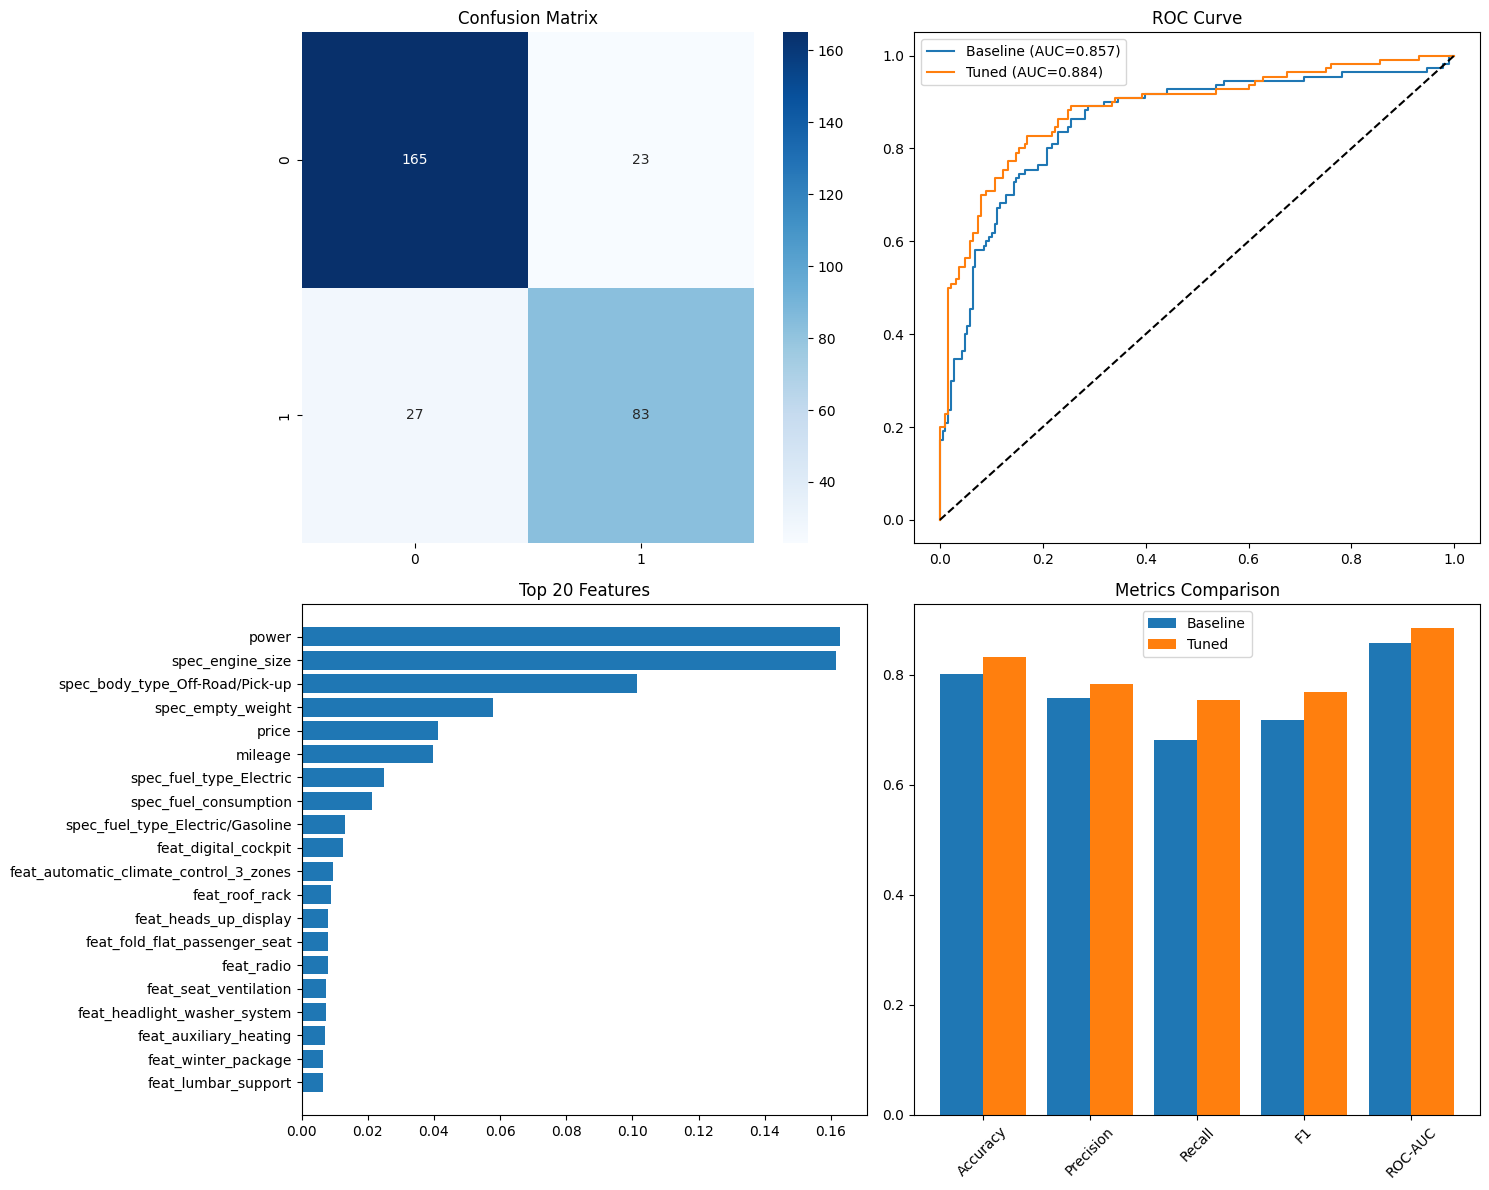

In [127]:

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Baseline
baseline_model = GradientBoostingClassifier(random_state=42)
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)
y_pred_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]

print("BASELINE:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_baseline):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_baseline):.4f}")
print(f"F1: {f1_score(y_test, y_pred_baseline):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_baseline):.4f}")

# Grid Search
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 0.9, 1.0],
    'max_features': ['sqrt', 'log2', None]
}

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("\nBEST PARAMS:")
print(grid_search.best_params_)
print(f"CV ROC-AUC: {grid_search.best_score_:.4f}")

# Test
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
y_pred_proba_tuned = best_model.predict_proba(X_test)[:, 1]

print("\nTUNED:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1: {f1_score(y_test, y_pred_tuned):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_tuned):.4f}")

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_tuned))

# Plot
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Confusion Matrix')

# ROC Curve
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_pred_proba_baseline)
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_pred_proba_tuned)
axes[0, 1].plot(fpr_baseline, tpr_baseline, label=f'Baseline (AUC={roc_auc_score(y_test, y_pred_proba_baseline):.3f})')
axes[0, 1].plot(fpr_tuned, tpr_tuned, label=f'Tuned (AUC={roc_auc_score(y_test, y_pred_proba_tuned):.3f})')
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set_title('ROC Curve')
axes[0, 1].legend()

# Feature Importance
fi = pd.DataFrame({'feature': X.columns, 'importance': best_model.feature_importances_}).sort_values('importance', ascending=False).head(20)
axes[1, 0].barh(range(len(fi)), fi['importance'])
axes[1, 0].set_yticks(range(len(fi)))
axes[1, 0].set_yticklabels(fi['feature'])
axes[1, 0].set_title('Top 20 Features')
axes[1, 0].invert_yaxis()

# Metrics Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
baseline_scores = [accuracy_score(y_test, y_pred_baseline), precision_score(y_test, y_pred_baseline), 
                   recall_score(y_test, y_pred_baseline), f1_score(y_test, y_pred_baseline), 
                   roc_auc_score(y_test, y_pred_proba_baseline)]
tuned_scores = [accuracy_score(y_test, y_pred_tuned), precision_score(y_test, y_pred_tuned), 
                recall_score(y_test, y_pred_tuned), f1_score(y_test, y_pred_tuned), 
                roc_auc_score(y_test, y_pred_proba_tuned)]
x = np.arange(len(metrics))
axes[1, 1].bar(x - 0.2, baseline_scores, 0.4, label='Baseline')
axes[1, 1].bar(x + 0.2, tuned_scores, 0.4, label='Tuned')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(metrics, rotation=45)
axes[1, 1].set_title('Metrics Comparison')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

-------
### **eXplainability** 

In [128]:
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:

# =============================================================================
# PREPARAZIONE DATI 
# =============================================================================

# Rimuovi colonne
columns_to_remove = ['comfort', 'interior', 'performance', 'value', 'exterior', 'reliability', 'PC1', 'make', 'model', 'cumulata', 'appreciate', 'id']
existing_columns_to_remove = [col for col in columns_to_remove if col in total_df.columns]

y = total_df['appreciate']
X = total_df.drop(columns=existing_columns_to_remove)

# Rimuovi colonne object
object_cols = X.select_dtypes(include=['object']).columns
if len(object_cols) > 0:
    X = X.drop(columns=object_cols)

# Converti booleani
bool_cols = X.select_dtypes(include=['bool']).columns
if len(bool_cols) > 0:
    X[bool_cols] = X[bool_cols].astype(int)

# Gestisci NaN
if X.isnull().sum().sum() > 0:
    for col in X.columns:
        if X[col].isnull().sum() > 0:
            X[col].fillna(X[col].median(), inplace=True)

# Usa gli stessi indici del modello già trainato
X_train = X.loc[y_train.index]
X_test = X.loc[y_test.index]


In [134]:

# =============================================================================
# LIME - SPIEGAZIONI LOCALI
# =============================================================================

explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['Not Appreciate', 'Appreciate'],
    mode='classification',
    random_state=42
)

def get_lime_explanation(instance_idx, num_features=20):
    instance = X_test.iloc[instance_idx].values
    exp = explainer.explain_instance(
        instance,
        best_model.predict_proba,
        num_features=num_features
    )
    return exp

# =============================================================================
# ESTENSIONE GLOBALE - AGGREGAZIONE LIME
# =============================================================================

def compute_global_lime_importance(X_sample, num_samples=200, num_features=20):
    if len(X_sample) > num_samples:
        sample_indices = np.random.choice(len(X_sample), num_samples, replace=False)
    else:
        sample_indices = np.arange(len(X_sample))
    
    feature_importances = {feat: [] for feat in X_sample.columns}
    
    print(f"Calcolando LIME per {len(sample_indices)} istanze...")
    for i, idx in enumerate(sample_indices):
        if i % 20 == 0:
            print(f"  Progresso: {i}/{len(sample_indices)}")
        
        instance = X_sample.iloc[idx].values
        exp = explainer.explain_instance(
            instance,
            best_model.predict_proba,
            num_features=num_features
        )
        
        for feat, weight in exp.as_list():
            feat_name = feat.split()[0] if ' ' in feat else feat
            for col in X_sample.columns:
                if col in feat or feat_name == col:
                    feature_importances[col].append(abs(weight))
                    break
    
    global_importance = {}
    for feat, weights in feature_importances.items():
        if weights:
            global_importance[feat] = {
                'mean': np.mean(weights),
                'std': np.std(weights),
                'count': len(weights)
            }
        else:
            global_importance[feat] = {
                'mean': 0,
                'std': 0,
                'count': 0
            }
    
    return pd.DataFrame(global_importance).T.sort_values('mean', ascending=False)

global_lime_importance = compute_global_lime_importance(X_test, num_samples=200)


Calcolando LIME per 200 istanze...
  Progresso: 0/200
  Progresso: 20/200
  Progresso: 40/200
  Progresso: 60/200
  Progresso: 80/200
  Progresso: 100/200
  Progresso: 120/200
  Progresso: 140/200
  Progresso: 160/200
  Progresso: 180/200


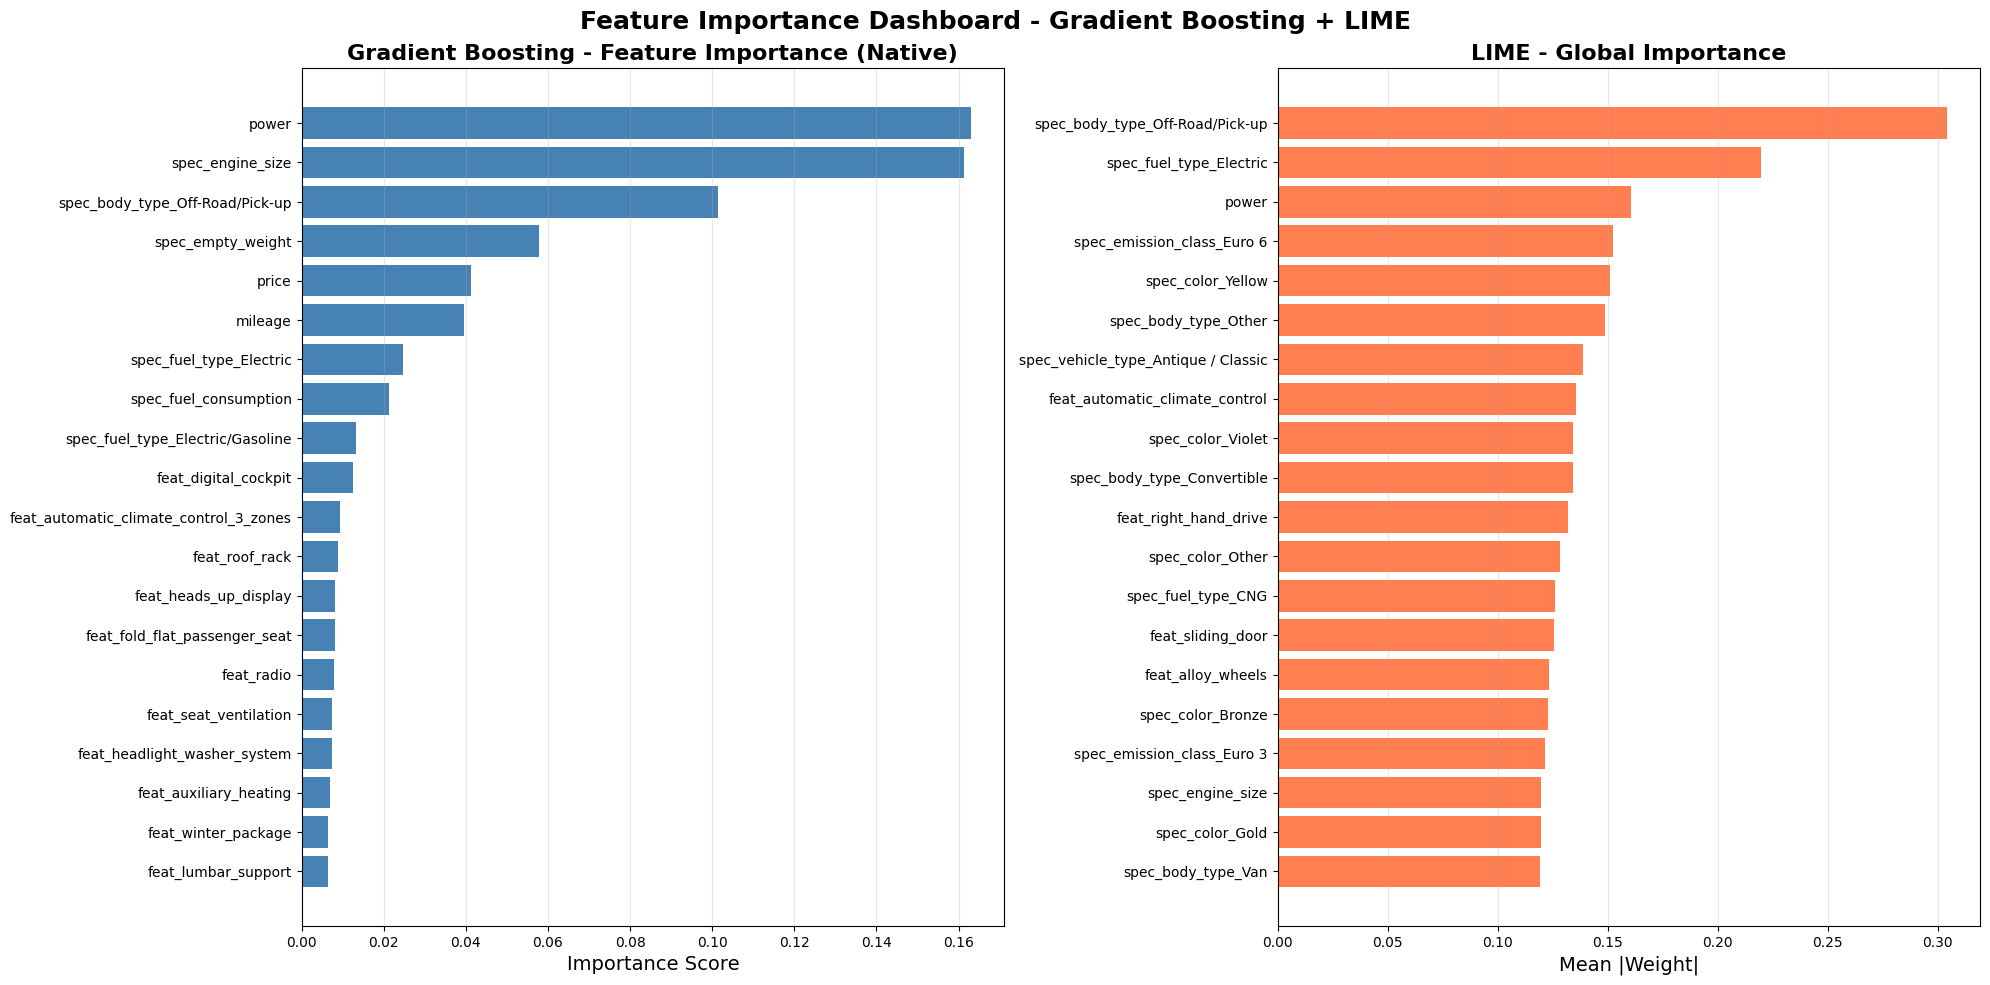


FEATURE IMPORTANCE STATISTICS

Top 10 Features - Gradient Boosting (Native):
                         feature  importance
                           power    0.162921
                spec_engine_size    0.161418
 spec_body_type_Off-Road/Pick-up    0.101376
               spec_empty_weight    0.057881
                           price    0.041189
                         mileage    0.039621
         spec_fuel_type_Electric    0.024788
           spec_fuel_consumption    0.021273
spec_fuel_type_Electric/Gasoline    0.013202
            feat_digital_cockpit    0.012525

Top 10 Features - LIME Global (Aggregated):
                                         mean       std  count
spec_body_type_Off-Road/Pick-up      0.304004  0.009335  200.0
spec_fuel_type_Electric              0.219892  0.024235  200.0
power                                0.160419  0.046108  148.0
spec_emission_class_Euro 6           0.152394  0.054520  150.0
spec_color_Yellow                    0.150872  0.076184  123.0
spec

In [135]:
# =============================================================================
# DASHBOARD - FEATURE IMPORTANCE (SOLO GLOBALE)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# 1. Gradient Boosting Feature Importance
gb_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

axes[0].barh(range(len(gb_importance)), gb_importance['importance'], color='steelblue')
axes[0].set_yticks(range(len(gb_importance)))
axes[0].set_yticklabels(gb_importance['feature'])
axes[0].set_xlabel('Importance Score', fontsize=14)
axes[0].set_title('Gradient Boosting - Feature Importance (Native)', fontsize=16, fontweight='bold')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# 2. LIME Global Importance
top_lime = global_lime_importance.head(20)
axes[1].barh(range(len(top_lime)), top_lime['mean'], color='coral')
axes[1].set_yticks(range(len(top_lime)))
axes[1].set_yticklabels(top_lime.index)
axes[1].set_xlabel('Mean |Weight|', fontsize=14)
axes[1].set_title('LIME - Global Importance', fontsize=16, fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle('Feature Importance Dashboard - Gradient Boosting + LIME', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# =============================================================================
# STATISTICHE
# =============================================================================

print("\n" + "="*80)
print("FEATURE IMPORTANCE STATISTICS")
print("="*80)

print("\nTop 10 Features - Gradient Boosting (Native):")
print(gb_importance.head(10).to_string(index=False))

print("\nTop 10 Features - LIME Global (Aggregated):")
print(global_lime_importance.head(10))

print("\n" + "="*80)

In [139]:
# =============================================================================
# ESTENSIONE GLOBALE - AGGREGAZIONE LIME CON DIREZIONE
# =============================================================================

def compute_global_lime_importance_with_direction(X_sample, num_samples=100, num_features=20):
    """
    Aggrega spiegazioni LIME locali mantenendo la direzione (presenza/assenza)
    """
    if len(X_sample) > num_samples:
        sample_indices = np.random.choice(len(X_sample), num_samples, replace=False)
    else:
        sample_indices = np.arange(len(X_sample))
    
    # Dizionario per accumulare importanze CON SEGNO
    feature_importances_signed = {feat: [] for feat in X_sample.columns}
    feature_importances_abs = {feat: [] for feat in X_sample.columns}
    
    print(f"Calcolando LIME per {len(sample_indices)} istanze...")
    for i, idx in enumerate(sample_indices):
        if i % 20 == 0:
            print(f"  Progresso: {i}/{len(sample_indices)}")
        
        instance = X_sample.iloc[idx].values
        exp = explainer.explain_instance(
            instance,
            best_model.predict_proba,
            num_features=num_features
        )
        
        for feat, weight in exp.as_list():
            feat_name = feat.split()[0] if ' ' in feat else feat
            for col in X_sample.columns:
                if col in feat or feat_name == col:
                    feature_importances_signed[col].append(weight)  # CON SEGNO
                    feature_importances_abs[col].append(abs(weight))  # VALORE ASSOLUTO
                    break
    
    # Calcola statistiche
    global_importance = {}
    for feat in X_sample.columns:
        weights_signed = feature_importances_signed[feat]
        weights_abs = feature_importances_abs[feat]
        
        if weights_signed:
            global_importance[feat] = {
                'mean_signed': np.mean(weights_signed),  # Media CON segno
                'mean_abs': np.mean(weights_abs),  # Media valore assoluto
                'std': np.std(weights_signed),
                'positive_pct': np.sum(np.array(weights_signed) > 0) / len(weights_signed) * 100,  # % contributi positivi
                'count': len(weights_signed)
            }
        else:
            global_importance[feat] = {
                'mean_signed': 0,
                'mean_abs': 0,
                'std': 0,
                'positive_pct': 0,
                'count': 0
            }
    
    return pd.DataFrame(global_importance).T

# Calcola importanza globale con direzione
global_lime_importance_dir = compute_global_lime_importance_with_direction(X_test, num_samples=400)

# Ordina per valore assoluto ma mantieni il segno
global_lime_importance_dir = global_lime_importance_dir.sort_values('mean_abs', ascending=False)




Calcolando LIME per 298 istanze...
  Progresso: 0/298
  Progresso: 20/298
  Progresso: 40/298
  Progresso: 60/298
  Progresso: 80/298
  Progresso: 100/298
  Progresso: 120/298
  Progresso: 140/298
  Progresso: 160/298
  Progresso: 180/298
  Progresso: 200/298
  Progresso: 220/298
  Progresso: 240/298
  Progresso: 260/298
  Progresso: 280/298


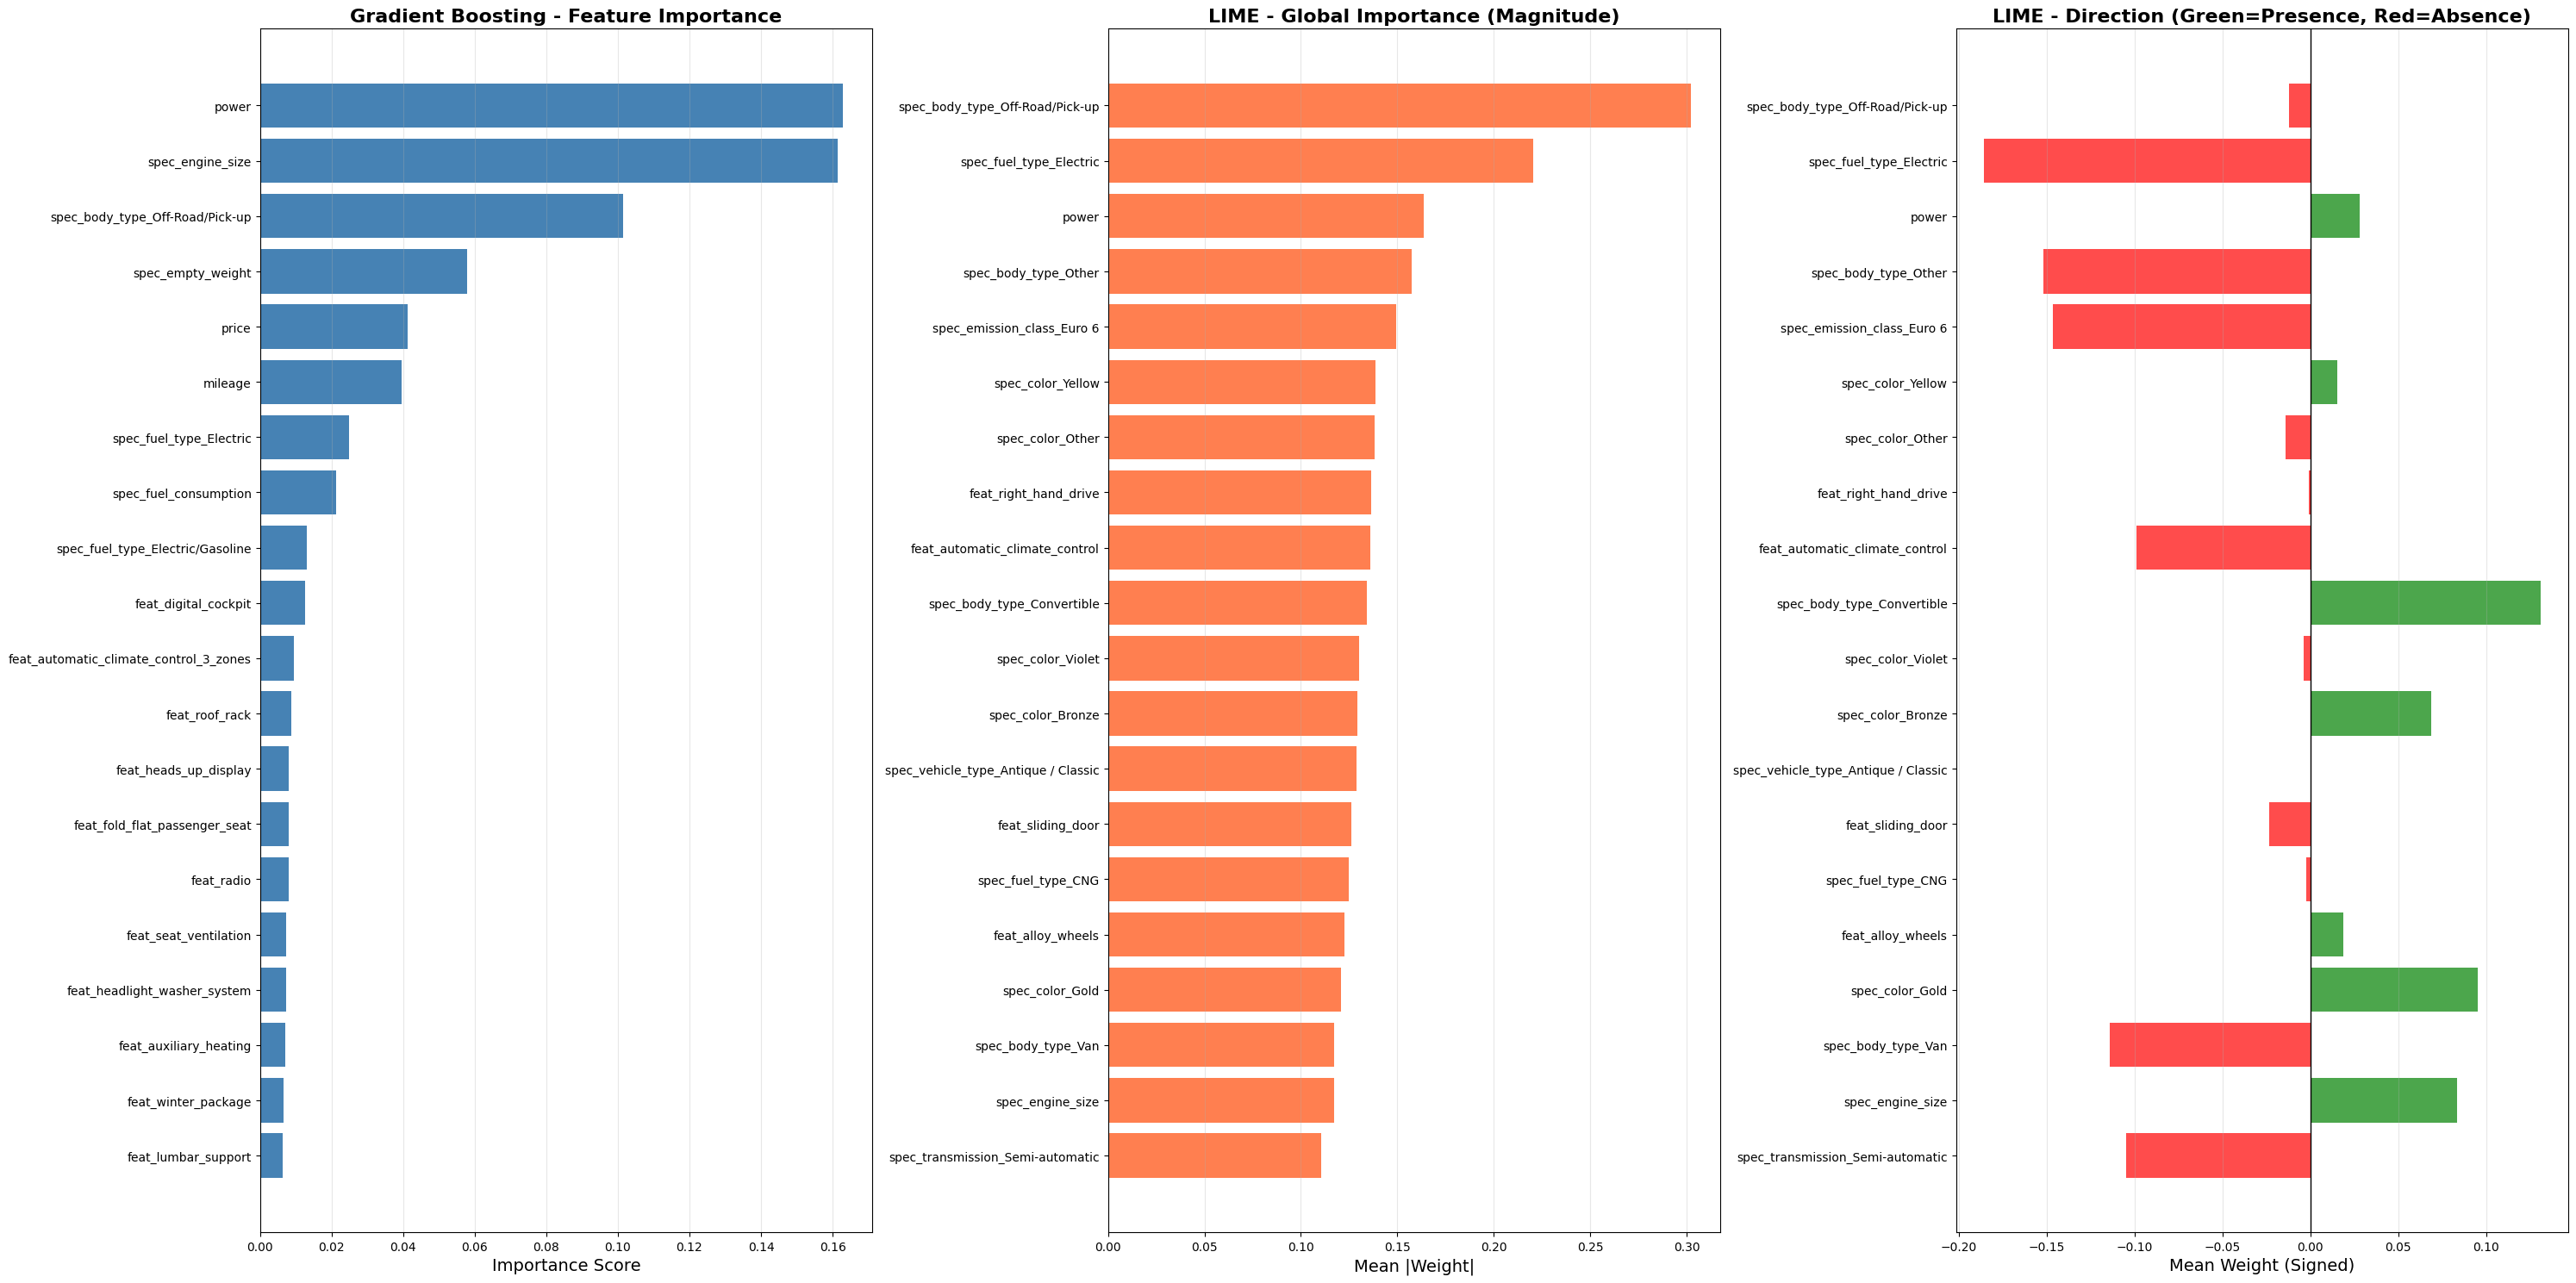


FEATURE IMPORTANCE WITH DIRECTION

Top 10 Features - LIME Global (With Direction):
----------------------------------------------------------------------------------------------------
Feature                                  Mean Weight     |Mean|          Positive %      Direction      
----------------------------------------------------------------------------------------------------
spec_body_type_Off-Road/Pick-up               -0.012285       0.302201           48.0% → Not Appreciate
spec_fuel_type_Electric                       -0.185841       0.220238            7.7% → Not Appreciate
power                                          0.027911       0.163537           49.3% → Appreciate   
spec_body_type_Other                          -0.151957       0.157320            1.5% → Not Appreciate
spec_emission_class_Euro 6                    -0.146717       0.149204            1.3% → Not Appreciate
spec_color_Yellow                              0.015236       0.138712           58.5% → A

In [142]:

fig, axes = plt.subplots(1, 3, figsize=(30, 15))

# 1. Gradient Boosting Feature Importance
gb_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

axes[0].barh(range(len(gb_importance)), gb_importance['importance'], color='steelblue')
axes[0].set_yticks(range(len(gb_importance)))
axes[0].set_yticklabels(gb_importance['feature'])
axes[0].set_xlabel('Importance Score', fontsize=14)
axes[0].set_title('Gradient Boosting - Feature Importance', fontsize=16, fontweight='bold')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# 2. LIME Global Importance (Valore Assoluto)
top_lime = global_lime_importance_dir.head(20)
axes[1].barh(range(len(top_lime)), top_lime['mean_abs'], color='coral')
axes[1].set_yticks(range(len(top_lime)))
axes[1].set_yticklabels(top_lime.index)
axes[1].set_xlabel('Mean |Weight|', fontsize=14)
axes[1].set_title('LIME - Global Importance (Magnitude)', fontsize=16, fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

# 3. LIME Global Importance CON DIREZIONE
colors_dir = ['green' if x > 0 else 'red' for x in top_lime['mean_signed']]
axes[2].barh(range(len(top_lime)), top_lime['mean_signed'], color=colors_dir, alpha=0.7)
axes[2].set_yticks(range(len(top_lime)))
axes[2].set_yticklabels(top_lime.index)
axes[2].set_xlabel('Mean Weight (Signed)', fontsize=14)
axes[2].set_title('LIME - Direction (Green=Presence, Red=Absence)', fontsize=16, fontweight='bold')
axes[2].invert_yaxis()
axes[2].axvline(x=0, color='black', linestyle='-', linewidth=1)
axes[2].grid(axis='x', alpha=0.3)

#plt.suptitle('Feature Importance Dashboard - With Direction', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# =============================================================================
# STATISTICHE CON DIREZIONE
# =============================================================================

print("\n" + "="*100)
print("FEATURE IMPORTANCE WITH DIRECTION")
print("="*100)

print("\nTop 10 Features - LIME Global (With Direction):")
print("-"*100)
print(f"{'Feature':<40} {'Mean Weight':<15} {'|Mean|':<15} {'Positive %':<15} {'Direction':<15}")
print("-"*100)

for idx, row in global_lime_importance_dir.head(10).iterrows():
    direction = "→ Appreciate" if row['mean_signed'] > 0 else "→ Not Appreciate"
    print(f"{idx:<40} {row['mean_signed']:>14.6f} {row['mean_abs']:>14.6f} {row['positive_pct']:>14.1f}% {direction:<15}")

print("\n" + "="*100)
print("INTERPRETAZIONE:")
print("="*100)
print("• Mean Weight > 0 (VERDE): La PRESENZA della feature aumenta la probabilità di 'Appreciate'")
print("• Mean Weight < 0 (ROSSO): L'ASSENZA della feature (o valori bassi) aumenta 'Appreciate'")
print("• Positive %: Percentuale di istanze dove la feature contribuisce positivamente")
print("="*100)